In [1]:
!pip install -U transformers accelerate -q

In [2]:
import torch
import numpy as np
import pandas as pd
import transformers

from torch.utils.data import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
    set_seed
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

set_seed(42)

print("Transformers version:", transformers.__version__)
print("PyTorch version:", torch.__version__)
print("Device:", "GPU" if torch.cuda.is_available() else "CPU")

Transformers version: 5.23.0
PyTorch version: 2.14.1+cu130
Device: GPU


In [3]:
en_train = pd.read_csv("/content/drive/MyDrive/Category-Aware Fake Review Detection/data/processed/processed/en_train.csv")
en_test = pd.read_csv("/content/drive/MyDrive/Category-Aware Fake Review Detection/data/processed/processed/en_test.csv")
en_val = pd.read_csv("/content/drive/MyDrive/Category-Aware Fake Review Detection/data/processed/processed/en_val.csv")

In [4]:
# Check dataset sizes
print("Training:", len(en_train))
print("Validation:", len(en_val))
print("Testing:", len(en_test))

# Check labels
print("\nTraining label distribution:")
print(en_train['label'].value_counts())

# Confirm label mapping
print("\nUnique labels:", en_train['label'].unique())

# Confirm fake/genuine mapping
FAKE_LABEL = 1
GENUINE_LABEL = 0

assert set(en_train['label'].unique()) == {0, 1}
assert set(en_val['label'].unique()) == {0, 1}
assert set(en_test['label'].unique()) == {0, 1}

print("\nLabel mapping:")
print("0 = Genuine")
print("1 = Fake")

Training: 29400
Validation: 6300
Testing: 6301

Training label distribution:
label
0    14706
1    14694
Name: count, dtype: int64

Unique labels: [1 0]

Label mapping:
0 = Genuine
1 = Fake


In [5]:
MODEL_NAME = "distilbert-base-uncased"

# Load tokenizer
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Load pretrained DistilBERT with a binary classification head
transformer_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    id2label={
        0: "Genuine",
        1: "Fake"
    },
    label2id={
        "Genuine": 0,
        "Fake": 1
    }
)

print("DistilBERT loaded successfully!")
print("Number of parameters:",
      sum(p.numel() for p in transformer_model.parameters()))

print("Trainable parameters:",
      sum(p.numel() for p in transformer_model.parameters()
          if p.requires_grad))

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


DistilBERT loaded successfully!
Number of parameters: 66955010
Trainable parameters: 66955010


In [6]:
MAX_LENGTH = 256

# Tokenize training reviews
train_encodings = tokenizer(
    en_train['review_text'].fillna("").astype(str).tolist(),
    truncation=True,
    max_length=MAX_LENGTH
)

# Tokenize validation reviews
val_encodings = tokenizer(
    en_val['review_text'].fillna("").astype(str).tolist(),
    truncation=True,
    max_length=MAX_LENGTH
)

# Tokenize test reviews
test_encodings = tokenizer(
    en_test['review_text'].fillna("").astype(str).tolist(),
    truncation=True,
    max_length=MAX_LENGTH
)

print("Tokenization completed!")

print("Training reviews:", len(train_encodings['input_ids']))
print("Validation reviews:", len(val_encodings['input_ids']))
print("Testing reviews:", len(test_encodings['input_ids']))

print("\nExample token IDs:")
print(train_encodings['input_ids'][0][:20])

Tokenization completed!
Training reviews: 29400
Validation reviews: 6300
Testing reviews: 6301

Example token IDs:
[101, 1045, 5632, 2023, 2143, 1998, 2009, 2038, 2921, 2033, 5117, 1999, 1996, 2381, 1997, 2023, 2307, 2143, 1012, 2009]


In [7]:
class FakeReviewDataset(Dataset):

    def __init__(self, encodings, labels):

        self.encodings = encodings
        self.labels = labels.tolist()

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):

        item = {
            key: torch.tensor(val[idx])
            for key, val in self.encodings.items()
        }

        item['labels'] = torch.tensor(
            int(self.labels[idx]),
            dtype=torch.long
        )

        return item


# Create datasets
train_dataset = FakeReviewDataset(
    train_encodings,
    en_train['label']
)

val_dataset = FakeReviewDataset(
    val_encodings,
    en_val['label']
)

test_dataset = FakeReviewDataset(
    test_encodings,
    en_test['label']
)

print("PyTorch datasets created!")

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Testing samples:", len(test_dataset))

PyTorch datasets created!
Training samples: 29400
Validation samples: 6300
Testing samples: 6301


In [8]:
def compute_metrics(eval_pred):

    logits, labels = eval_pred

    # Convert logits into probabilities
    probabilities = torch.softmax(
        torch.tensor(logits),
        dim=1
    ).numpy()[:, 1]

    # Predict fake/genuine labels
    predictions = (probabilities >= 0.5).astype(int)

    return {
        "accuracy": accuracy_score(labels, predictions),

        "precision": precision_score(
            labels, predictions, zero_division=0
        ),

        "recall": recall_score(
            labels, predictions, zero_division=0
        ),

        "f1": f1_score(
            labels, predictions, zero_division=0
        ),

        "roc_auc": roc_auc_score(
            labels, probabilities
        )
    }


# Dynamic padding: pad each batch to its longest review
data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

print("Evaluation metrics and data collator configured!")

Evaluation metrics and data collator configured!


In [9]:
training_args = TrainingArguments(

    output_dir="./distilbert_fake_review",

    # Evaluate after every epoch
    eval_strategy="epoch",

    # Save after every epoch
    save_strategy="epoch",

    # Training settings
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,

    num_train_epochs=3,
    weight_decay=0.01,

    # Select best checkpoint using validation F1
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,

    # GPU optimization
    fp16=torch.cuda.is_available(),

    # Logging and saving
    logging_steps=100,
    save_total_limit=1,

    report_to="none",
    seed=42
)

print("Training configuration completed!")

Training configuration completed!


In [10]:
trainer = Trainer(

    model=transformer_model,

    args=training_args,

    train_dataset=train_dataset,

    eval_dataset=val_dataset,

    data_collator=data_collator,

    compute_metrics=compute_metrics
)

print("Starting DistilBERT fine-tuning...")

train_output = trainer.train()

print("\nDistilBERT fine-tuning completed!")

Starting DistilBERT fine-tuning...


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,Roc Auc
1,0.110677,0.139382,0.962857,0.944733,0.983159,0.963563,0.995418
2,0.074825,0.149934,0.966190,0.947802,0.986654,0.966838,0.996716
3,0.012828,0.195120,0.967619,0.948491,0.988878,0.968264,0.996515


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


DistilBERT fine-tuning completed!


In [11]:
print("BEST VALIDATION RESULTS")
print("------------------------")

val_results = trainer.evaluate()

for metric, value in val_results.items():

    if isinstance(value, (int, float)):
        print(f"{metric}: {value:.4f}")

BEST VALIDATION RESULTS
------------------------


Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1,Roc Auc
0.012828,0.195120,3,0.967619,0.948491,0.988878,0.968264,0.996515


eval_loss: 0.1951
eval_accuracy: 0.9676
eval_precision: 0.9485
eval_recall: 0.9889
eval_f1: 0.9683
eval_roc_auc: 0.9965


In [13]:
# Get the actual test labels
y_test = en_test['label'].astype(int).values
# Generate predictions on test data
test_output = trainer.predict(test_dataset)

# Extract logits
test_logits = test_output.predictions

# Convert logits into probabilities
transformer_test_probabilities = torch.softmax(
    torch.tensor(test_logits),
    dim=1
).numpy()[:, 1]

# Generate final predictions
transformer_test_predictions = np.where(
    transformer_test_probabilities >= 0.5,
    FAKE_LABEL,
    GENUINE_LABEL
)

# Calculate metrics
print("DISTILBERT - FINAL TEST RESULTS")
print("--------------------------------")

print("Accuracy:",
      accuracy_score(y_test, transformer_test_predictions))

print("Precision:",
      precision_score(
          y_test, transformer_test_predictions,
          pos_label=FAKE_LABEL
      ))

print("Recall:",recall_score(y_test, transformer_test_predictions,pos_label=FAKE_LABEL))

print("F1 Score:", f1_score(y_test, transformer_test_predictions,pos_label=FAKE_LABEL))

print("ROC-AUC:",roc_auc_score((y_test == FAKE_LABEL).astype(int),transformer_test_probabilities))

print("\nClassification Report:")

print(classification_report(y_test, transformer_test_predictions,labels=[GENUINE_LABEL, FAKE_LABEL],target_names=['Genuine', 'Fake'],zero_division=0))

DISTILBERT - FINAL TEST RESULTS
--------------------------------
Accuracy: 0.9687351214093001
Precision: 0.948905109489051
Recall: 0.9907907272149888
F1 Score: 0.9693956812179587
ROC-AUC: 0.9972160507807653

Classification Report:
              precision    recall  f1-score   support

     Genuine       0.99      0.95      0.97      3152
        Fake       0.95      0.99      0.97      3149

    accuracy                           0.97      6301
   macro avg       0.97      0.97      0.97      6301
weighted avg       0.97      0.97      0.97      6301



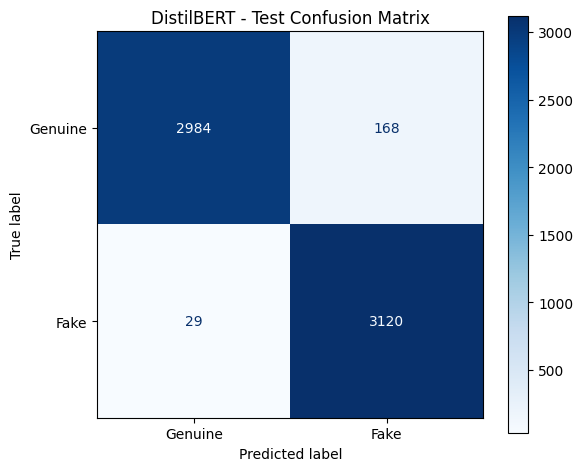

In [14]:
fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    transformer_test_predictions,
    labels=[GENUINE_LABEL, FAKE_LABEL],
    display_labels=['Genuine', 'Fake'],
    cmap='Blues',
    ax=ax
)

plt.title("DistilBERT - Test Confusion Matrix")
plt.tight_layout()
plt.show()

In [15]:
# Save model and tokenizer
trainer.save_model("./final_distilbert_fake_review")

tokenizer.save_pretrained(
    "./final_distilbert_fake_review"
)

print("Fine-tuned DistilBERT saved successfully!")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Fine-tuned DistilBERT saved successfully!


In [21]:
import os

BASE_PATH = "/content/drive/MyDrive/Category-Aware Fake Review Detection"

files_to_check = [
    "english_tfidf_vectorizer.pkl",
    "english_logistic_regression.pkl",
    "english_category_model.pkl",
    "english_category_aware_model.pkl"
]

for filename in files_to_check:
    path = os.path.join(BASE_PATH, filename)

    with open(path, "rb") as f:
        header = f.read(20)

    print("\nFile:", filename)
    print("Size:", os.path.getsize(path), "bytes")
    print("First 20 bytes:", header)


File: english_tfidf_vectorizer.pkl
Size: 3960449 bytes
First 20 bytes: b'\x80\x04\x95\xc3\x02\x00\x00\x00\x00\x00\x00\x8c\x1fsklearn'

File: english_logistic_regression.pkl
Size: 800879 bytes
First 20 bytes: b'\x80\x04\x95\x13\x02\x00\x00\x00\x00\x00\x00\x8c\x1esklearn'

File: english_category_model.pkl
Size: 8801279 bytes
First 20 bytes: b'\x80\x04\x95\x13\x02\x00\x00\x00\x00\x00\x00\x8c\x1esklearn'

File: english_category_aware_model.pkl
Size: 800975 bytes
First 20 bytes: b'\x80\x04\x95\x13\x02\x00\x00\x00\x00\x00\x00\x8c\x1esklearn'


In [22]:
import joblib
import os

BASE_PATH = "/content/drive/MyDrive/Category-Aware Fake Review Detection"

tfidf_vectorizer = joblib.load(
    os.path.join(BASE_PATH, "english_tfidf_vectorizer.pkl")
)

lr_model = joblib.load(
    os.path.join(BASE_PATH, "english_logistic_regression.pkl")
)

category_model = joblib.load(
    os.path.join(BASE_PATH, "english_category_model.pkl")
)

category_aware_model = joblib.load(
    os.path.join(BASE_PATH, "english_category_aware_model.pkl")
)

print("All four models loaded successfully!")

print("\nModel details:")
print("TF-IDF features:", len(tfidf_vectorizer.get_feature_names_out()))
print("Model 1:", type(lr_model).__name__)
print("Model 2:", type(category_model).__name__)
print("Model 3:", type(category_aware_model).__name__)

All four models loaded successfully!

Model details:
TF-IDF features: 100000
Model 1: LogisticRegression
Model 2: LogisticRegression
Model 3: LogisticRegression


In [26]:
import pandas as pd
import numpy as np
import os

DATA_PATH = os.path.join(
    BASE_PATH, "data", "processed", "processed"
)

en_test = pd.read_csv(
    os.path.join(DATA_PATH, "en_test.csv")
)

y_test = en_test["label"].astype(int).values

FAKE_LABEL = 1
GENUINE_LABEL = 0

print("Test dataset:", en_test.shape)
print("Test labels:", np.unique(y_test))


import pandas as pd
import numpy as np
import os

DATA_PATH = os.path.join(
    BASE_PATH, "data", "processed", "processed"
)

en_test = pd.read_csv(
    os.path.join(DATA_PATH, "en_test.csv")
)

y_test = en_test["label"].astype(int).values

FAKE_LABEL = 1
GENUINE_LABEL = 0

print("Test dataset:", en_test.shape)
print("Test labels:", np.unique(y_test))



X_test_tfidf = tfidf_vectorizer.transform(
    en_test["review_text"].fillna("").astype(str)
)

baseline_prob = lr_model.predict_proba(
    X_test_tfidf
)[:, list(lr_model.classes_).index(FAKE_LABEL)]

baseline_pred = (baseline_prob >= 0.5).astype(int)

print("Model 1 predictions generated!")


test_cat_predictions = category_model.predict(X_test_tfidf)

print("Category predictions generated!")
print("Predicted categories:", np.unique(test_cat_predictions))

print("TF-IDF features:", X_test_tfidf.shape[1])
print("Model 3 expected features:",
      category_aware_model.n_features_in_)

Test dataset: (6301, 3)
Test labels: [0 1]
Test dataset: (6301, 3)
Test labels: [0 1]
Model 1 predictions generated!
Category predictions generated!
Predicted categories: ['books' 'clothing shoes and jewelry' 'electronics' 'home and kitchen'
 'hotels' 'kindle store' 'movies and tv' 'pet supplies'
 'sports and outdoors' 'tools and home improvement' 'toys and games']
TF-IDF features: 100000
Model 3 expected features: 100011


In [27]:
from scipy.sparse import hstack, csr_matrix

category_names = [
    "kindle store",
    "books",
    "pet supplies",
    "home and kitchen",
    "electronics",
    "sports and outdoors",
    "tools and home improvement",
    "clothing shoes and jewelry",
    "toys and games",
    "movies and tv",
    "hotels"
]

# Create one-hot encoded category features
category_to_index = {
    category: index
    for index, category in enumerate(category_names)
}

category_encoded = np.zeros(
    (len(test_cat_predictions), len(category_names))
)

for i, category in enumerate(test_cat_predictions):
    if category in category_to_index:
        category_encoded[i, category_to_index[category]] = 1

X_test_combined = hstack([
    X_test_tfidf,
    csr_matrix(category_encoded)
])

print("Combined features:", X_test_combined.shape)
print("Expected features:", category_aware_model.n_features_in_)

assert X_test_combined.shape[1] == category_aware_model.n_features_in_, \
    "Feature count mismatch!"

Combined features: (6301, 100011)
Expected features: 100011


In [28]:
aware_prob = category_aware_model.predict_proba(
    X_test_combined
)[:, list(category_aware_model.classes_).index(FAKE_LABEL)]

aware_pred = (aware_prob >= 0.5).astype(int)

print("Model 3 predictions generated!")

Model 3 predictions generated!


In [29]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

def evaluate_model(y_true, predictions, probabilities):
    return {
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions),
        "Recall": recall_score(y_true, predictions),
        "F1 Score": f1_score(y_true, predictions),
        "ROC-AUC": roc_auc_score(y_true, probabilities)
    }

comparison = pd.DataFrame({
    "Model 1 - Text Only": evaluate_model(
        y_test, baseline_pred, baseline_prob
    ),
    "Model 3 - Category Aware": evaluate_model(
        y_test, aware_pred, aware_prob
    ),
    "Model 4 - DistilBERT": evaluate_model(
        y_test,
        transformer_test_predictions,
        transformer_test_probabilities
    )
})

display(comparison.round(4))

,Model 1 - Text Only,Model 3 - Category Aware,Model 4 - DistilBERT
Accuracy,0.9259,0.8976,0.9687
Precision,0.9449,0.9041,0.9489
Recall,0.9044,0.8895,0.9908
F1 Score,0.9242,0.8968,0.9694
ROC-AUC,0.9782,0.9545,0.9972
